<a href="https://colab.research.google.com/github/nandhadhev/machine-learning/blob/main/experiment_8.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

In [2]:
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import accuracy_score, classification_report

In [7]:
import urllib.request
import os

# Download dataset if not already present
file_name = "Online Retail.xlsx"
if not os.path.exists(file_name):
    print("Downloading dataset...")
    url = "https://archive.ics.uci.edu/ml/machine-learning-databases/00352/Online%20Retail.xlsx"
    urllib.request.urlretrieve(url, file_name)
    print("Download complete.")

# Load dataset
df = pd.read_excel(file_name)

# Remove missing CustomerID
df = df.dropna(subset=["CustomerID"])

# Remove invalid transactions
df = df[(df["Quantity"] > 0) & (df["UnitPrice"] > 0)]

# Calculate total amount
df["TotalAmount"] = df["Quantity"] * df["UnitPrice"]

# Customer-level aggregation
customer_data = df.groupby("CustomerID").agg({
    "Quantity": "sum",
    "TotalAmount": "sum",
    "InvoiceNo": "nunique"
}).reset_index()

customer_data.columns = [
    "CustomerID", "TotalQuantity",
    "TotalAmount", "NumberOfInvoices"
]

Download complete.


Accuracy: 0.9078

Classification Report:
              precision    recall  f1-score   support

           0       0.91      0.91      0.91       434
           1       0.91      0.91      0.91       434

    accuracy                           0.91       868
   macro avg       0.91      0.91      0.91       868
weighted avg       0.91      0.91      0.91       868



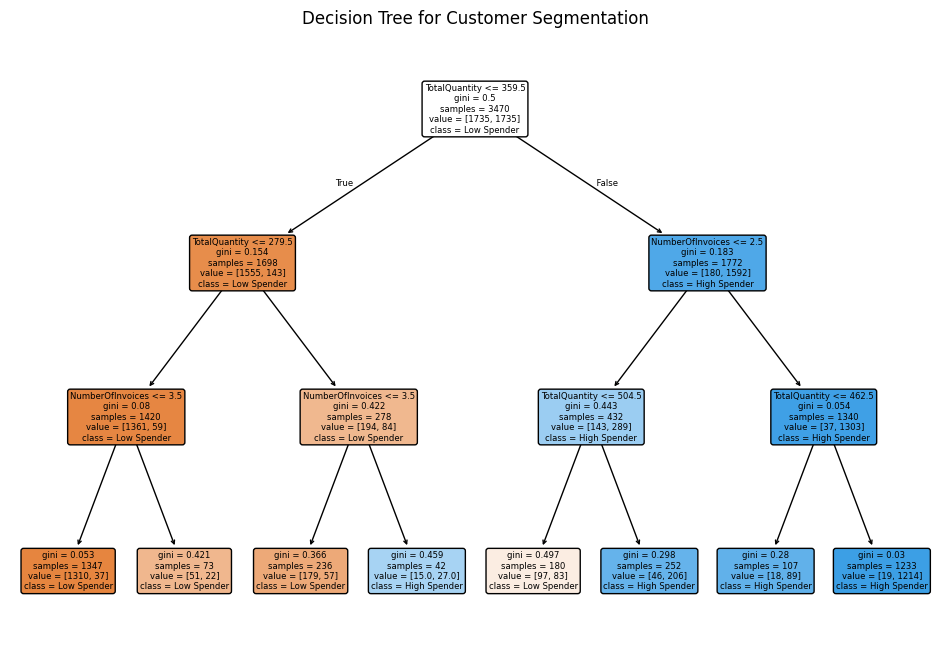

In [8]:
# Create customer segment (1 if TotalAmount >= median, 0 otherwise)
median_amount = customer_data["TotalAmount"].median()
customer_data["Segment"] = (
    customer_data["TotalAmount"] >= median_amount
).astype(int)

# Features and target
X = customer_data[["TotalQuantity", "NumberOfInvoices"]]
y = customer_data["Segment"]

# Split dataset
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# Train Decision Tree Classifier
clf = DecisionTreeClassifier(max_depth=3, random_state=42)
clf.fit(X_train, y_train)

# Predict and evaluate
y_pred = clf.predict(X_test)
print(f"Accuracy: {accuracy_score(y_test, y_pred):.4f}\n")
print("Classification Report:")
print(classification_report(y_test, y_pred))

# Visualize the Decision Tree
plt.figure(figsize=(12, 8))
plot_tree(clf, feature_names=X.columns, class_names=["Low Spender", "High Spender"], filled=True, rounded=True)
plt.title("Decision Tree for Customer Segmentation")
plt.show()

In [9]:
# Create customer segment
median_amount = customer_data["TotalAmount"].median()
customer_data["Segment"] = (
    customer_data["TotalAmount"] >= median_amount
).astype(int)

# Features and target
X = customer_data[["TotalQuantity", "NumberOfInvoices"]]
y = customer_data["Segment"]

In [10]:
# Split dataset
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# ID3 Decision Tree
model = DecisionTreeClassifier(
    criterion="entropy",
    max_depth=4,
    random_state=42
)
model.fit(X_train, y_train)


DecisionTreeClassifier(criterion='entropy', max_depth=4, random_state=42)

In [11]:
# Prediction
y_pred = model.predict(X_test)

print("Decision Tree Accuracy:",
      round(accuracy_score(y_test, y_pred) * 100, 2), "%")

print("\nClassification Report:")
print(classification_report(y_test, y_pred))

print("\nFeature Importance:")
for feature, importance in zip(
    X.columns, model.feature_importances_
):
    print(feature, ":", round(importance, 4))

Decision Tree Accuracy: 90.32 %

Classification Report:
              precision    recall  f1-score   support

           0       0.92      0.89      0.90       434
           1       0.89      0.92      0.90       434

    accuracy                           0.90       868
   macro avg       0.90      0.90      0.90       868
weighted avg       0.90      0.90      0.90       868


Feature Importance:
TotalQuantity : 0.8638
NumberOfInvoices : 0.1362


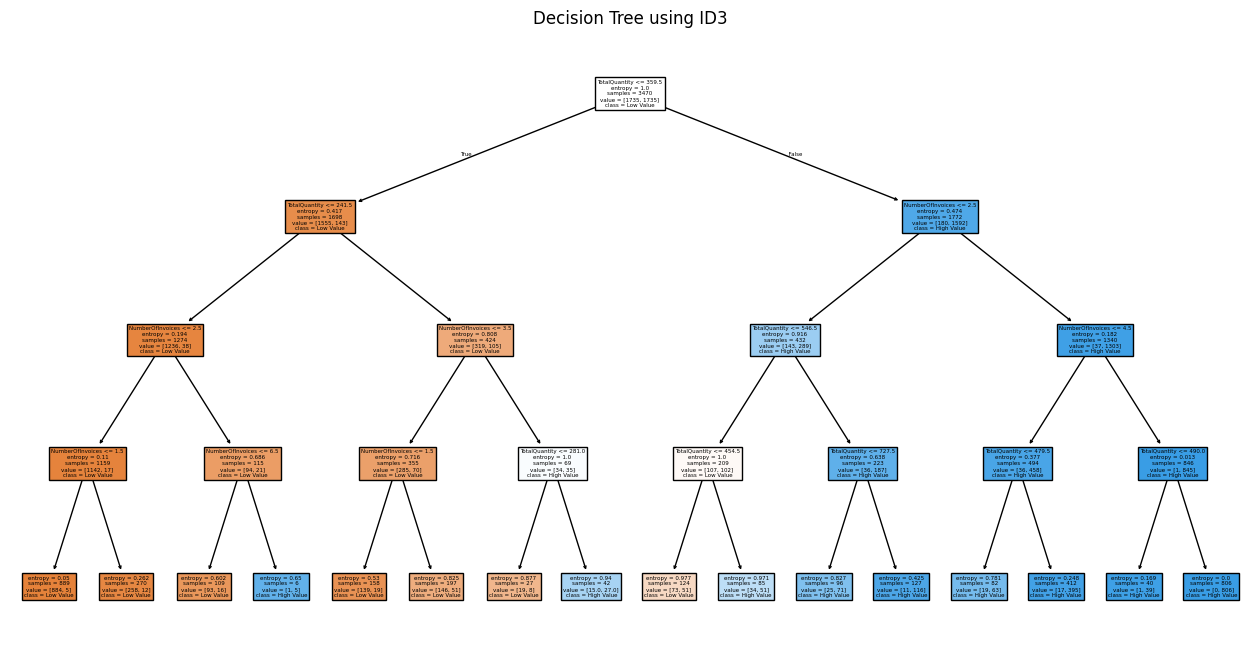

In [12]:
# Visualize tree
plt.figure(figsize=(16, 8))
plot_tree(
    model,
    feature_names=X.columns,
    class_names=["Low Value", "High Value"],
    filled=True
)
plt.title("Decision Tree using ID3")
plt.show()
